In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.analysis.pixel_analysis import (
    analyze_pixel_statistics,
    find_extreme_images
)
from src.data.dicom_loader import load_dicom

In [2]:
image_dir = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_images"
)

print("Image directory:", image_dir)
print("Exists:", image_dir.exists())

Image directory: ..\data\raw\rsna-pneumonia-detection-challenge\stage_2_train_images
Exists: True


In [3]:
image_paths = list(image_dir.glob("*.dcm"))

print("Total DICOM images:", len(image_paths))

Total DICOM images: 26684


In [4]:
SAMPLE_SIZE = 1000
RANDOM_STATE = 42

pixel_df = analyze_pixel_statistics(
    image_dir=image_dir,
    sample_size=SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

print("Images analyzed:", len(pixel_df))

Images analyzed: 1000


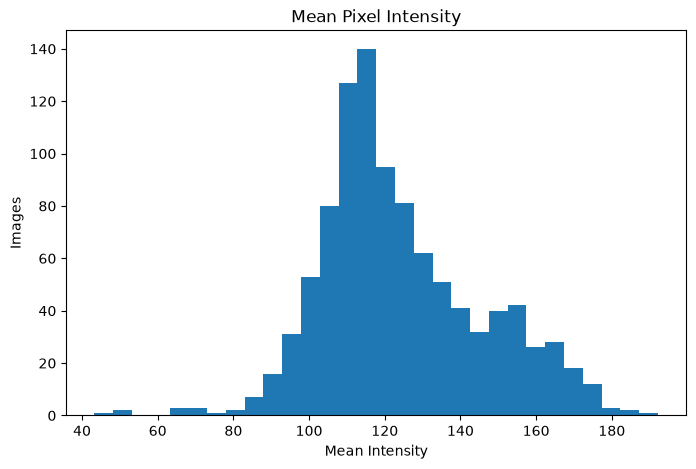

In [5]:
# Mean Brightness

plt.figure(figsize=(8,5))

plt.hist(
    pixel_df["mean_intensity"],
    bins=30
)

plt.title("Mean Pixel Intensity")

plt.xlabel("Mean Intensity")

plt.ylabel("Images")

plt.show()

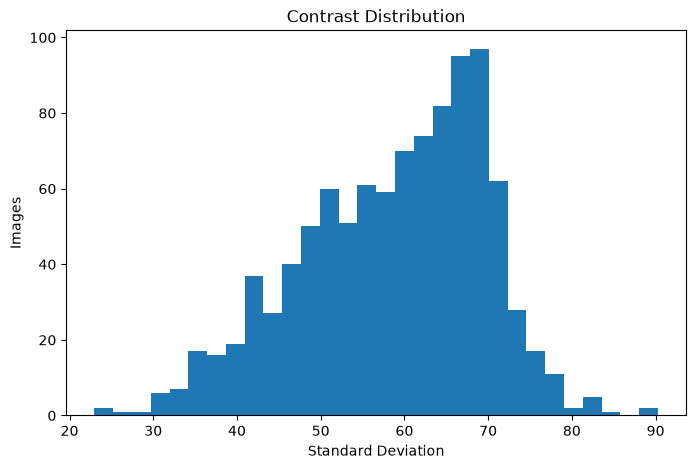

In [6]:
# Contrast

plt.figure(figsize=(8,5))

plt.hist(
    pixel_df["std_intensity"],
    bins=30
)

plt.title("Contrast Distribution")

plt.xlabel("Standard Deviation")

plt.ylabel("Images")

plt.show()

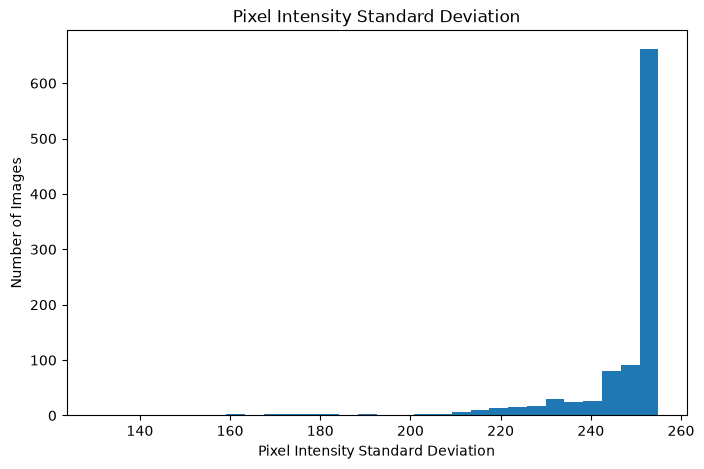

In [7]:
# Dynamic Range

plt.figure(figsize=(8,5))

plt.hist(
    pixel_df["dynamic_range"],
    bins=30
)

plt.title("Pixel Intensity Standard Deviation")
plt.xlabel("Pixel Intensity Standard Deviation")
plt.ylabel("Number of Images")

plt.show()

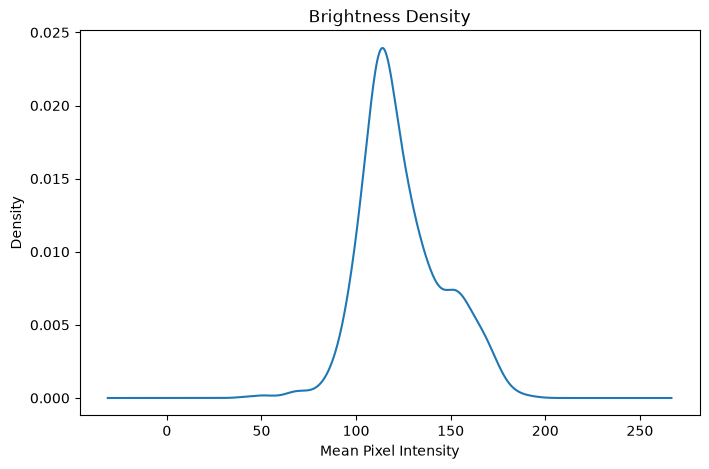

In [8]:
# Density Plot
pixel_df["mean_intensity"].plot(
    kind="density",
    figsize=(8,5)
)

plt.title("Brightness Density")
plt.xlabel("Mean Pixel Intensity")

plt.show()


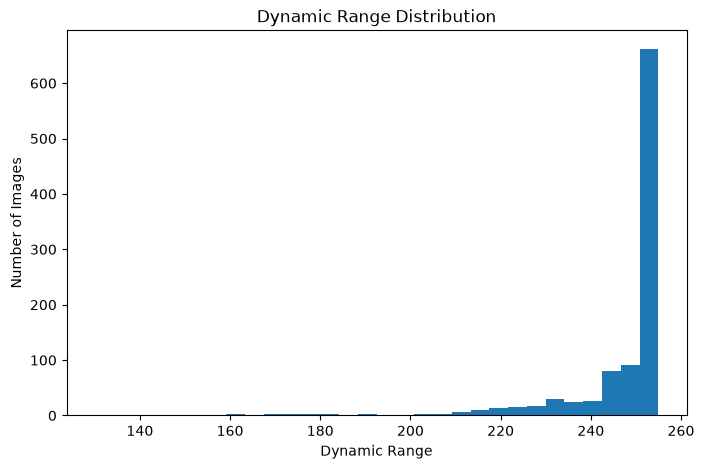

In [9]:
# Dynamic Range

plt.figure(figsize=(8, 5))

plt.hist(
    pixel_df["dynamic_range"],
    bins=30
)

plt.title("Dynamic Range Distribution")
plt.xlabel("Dynamic Range")
plt.ylabel("Number of Images")

plt.show()

In [10]:
# Find Extremes

darkest, brightest = find_extreme_images(pixel_df)

print("Darkest images:")
display(darkest)

print("\nBrightest images:")
display(brightest)

Darkest images:


,patient_id,mean_intensity,median_intensity,std_intensity,min_intensity,max_intensity,dynamic_range
245,953f8c8a-570a-4c40-b24c-cd919ae1c7f1,43.260609,42.0,22.964005,0.0,237.0,237.0
911,c9ded3c3-2032-409b-bc47-f851e236f8fd,51.683289,41.0,37.695950,0.0,255.0,255.0
185,c769a155-25b3-450e-a5b4-f29d447fc8c8,52.475117,31.0,55.102749,0.0,255.0,255.0
358,e7deadde-c104-446c-a75f-f200c31eee66,64.600563,44.0,66.044693,0.0,236.0,236.0
485,f25fbd2a-7adc-4701-95c4-549983ce8aa7,67.447937,55.0,64.394470,0.0,255.0,255.0



Brightest images:


,patient_id,mean_intensity,median_intensity,std_intensity,min_intensity,max_intensity,dynamic_range
364,b3207c07-7b40-4208-92e3-156de1fcbbdf,192.195175,202.0,24.477175,95.0,225.0,130.0
347,45aea8c6-d678-49d2-bdce-229f039468d8,186.259872,201.0,60.056499,0.0,255.0,255.0
589,3fa9f026-6175-4e8d-b6eb-e42bf92ba727,183.500229,199.0,50.722454,5.0,252.0,247.0
708,5511f7bb-6023-42ff-acc6-85e8f0a2c389,181.839417,196.0,50.141026,0.0,255.0,255.0
908,d260ebd9-6e46-4852-8eee-35e3234ac2b7,180.395416,195.0,64.974556,0.0,255.0,255.0


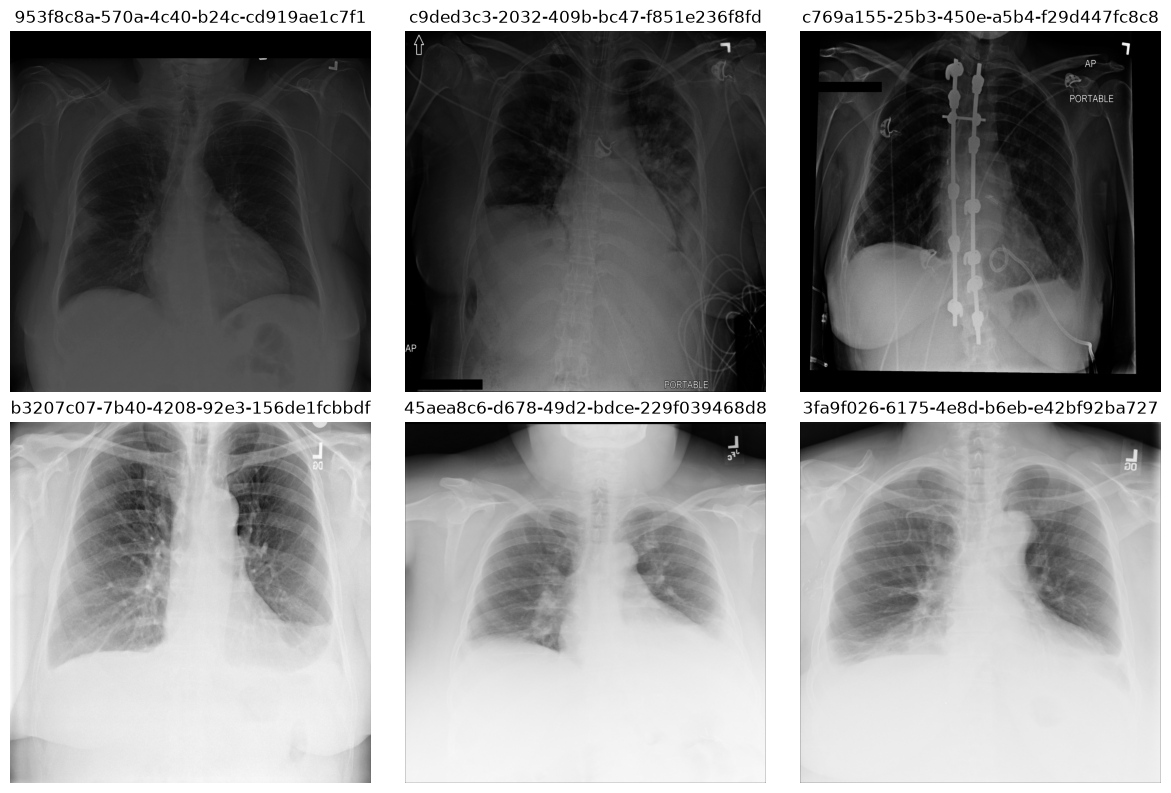

In [11]:
# Display Extreme Images

darkest_ids = darkest["patient_id"].tolist()
brightest_ids = brightest["patient_id"].tolist()

sample_ids = darkest_ids[:3] + brightest_ids[:3]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 8)
)

for ax, patient_id in zip(axes.flatten(), sample_ids):

    image, _ = load_dicom(
        image_dir / f"{patient_id}.dcm"
    )

    ax.imshow(
        image,
        cmap="gray"
    )

    ax.set_title(patient_id)
    ax.axis("off")

plt.tight_layout()
plt.show()